# IND320 - Project 2: Data to Decision

**Student:** Giorgio Crupi  
**GitHub Repository:** [https://github.com/giorgiocrupi/giorgiocrupi-ind320-project1](https://github.com/giorgiocrupi/giorgiocrupi-ind320-project1)  
**Streamlit App:** [https://giorgiocrupi-giorgiocrupi-ind320-project1-app-4zntut.streamlit.app/](https://giorgiocrupi-giorgiocrupi-ind320-project1-app-4zntut.streamlit.app/)  
**Sreen recording:** (https://eduumb-my.sharepoint.com/:v:/g/personal/gicru8998_nmbu_no/IQDuWz2sZFUUQLl-SwaC4ajpAZc27GILr4ZQVtI6zvVsid4?nav=eyJyZWZlcnJhbEluZm8iOnsicmVmZXJyYWxBcHAiOiJPbmVEcml2ZUZvckJ1c2luZXNzIiwicmVmZXJyYWxBcHBQbGF0Zm9ybSI6IldlYiIsInJlZmVycmFsTW9kZSI6InZpZXciLCJyZWZlcnJhbFZpZXciOiJNeUZpbGVzTGlua0NvcHkifX0&e=5Mx85n)

*Panopto wasn't working, log in the video with your @nmbu.no account*

## AI Usage Declaration

In this second part of the project I used AI more extensively than in the first, mainly Claude (Anthropic) and, to a lesser extent, Gemini. The AI acted as a step-by-step programming assistant: it proposed code and configurations, while I ran every step on my own machine, checked the outputs, reported errors back and made the decisions on how to proceed. I read every piece of generated code and connected it to the theory covered in class; whenever a choice was unclear, I asked the AI to explain why it had been made. Overall, the AI helped me considerably, but it also allowed me to learn a large number of new tools in a short time.

## Mandatory Work Report

The goal of this second part was to replace the static CSV file with live API connections and to build a complete data pipeline: ENTSO-E API → Spark → Cassandra → Spark → MongoDB → Streamlit.

The first and most time-consuming obstacle appeared when writing data from Spark to Cassandra. Every attempt failed immediately with a `java.lang.NoSuchMethodError`. At first I suspected a Java version problem, but the real cause was a Scala binary incompatibility: my Python 3.13 environment had installed PySpark 4.2, which runs on Scala 2.13, while the Spark Cassandra Connector is only built for Spark 3.5 and Scala 2.12. I solved it by creating a dedicated conda environment with Python 3.12, PySpark 3.5 and Java 17, together with the matching connector version. This taught me that in a data pipeline every component (Python, Java, Scala, Spark and the connector) has to be version-compatible.

A side effect of this solution is that the project now uses two separate kernels: the original uv environment for the Project 1 notebook and the Streamlit app, and the new Spark environment for the API extraction notebook. Old cells suddenly stopped working until I understood that each notebook remembers its own kernel, and that all variables are lost after switching or restarting it.

Retrieving two years of cross-border flows for three Norwegian interconnections, in both directions, was also not trivial: a single two-year request hung on the ENTSO-E server, so the data is now requested month by month with a timeout and cached locally. Since some series are published every 15 minutes and others hourly, I aggregated everything to hourly values in Spark before creating the pie chart and the line chart, and before storing the result in MongoDB Atlas.

Connecting to MongoDB caused several issues: the connection was refused when my IP address changed, the Streamlit app failed authentication because the password in its secrets file did not match the working one. These problems showed me the importance of keeping credentials outside the code (in `.env` and Streamlit secrets) and of configuring network access correctly.

Finally, I updated the Streamlit app: the reservoir pages now read from the NVE Magasinstatistikk API, radio buttons select the area type, and a new page reads the cross-border flows from MongoDB. With one line per area, the Min-Max normalised "All Columns" chart would have become unreadable, so I replaced it with one panel per variable, each in its real unit.

#### Environment check
Confirms that the notebook kernel uses Python 3.12 and PySpark 3.5.

In [1]:
import sys, pyspark
print(sys.version)
print(pyspark.__version__)

3.12.15 (main, Oct  7 2026, 00:00:10) [Clang 21.1.8 ]
3.5.9


### API access and NVE reservoir data

As required, the local CSV file with reservoir statistics has been replaced by a **direct API connection**.

- **ENTSO-E token**: loaded from a local `.env` file with `python-dotenv`, so the
  personal API key is never written in the notebook or pushed to GitHub.
- **NVE Magasinstatistikk API**: a public endpoint from the Norwegian Water Resources and
  Energy Directorate that returns weekly reservoir statistics (filling rate, capacity, volume)
  for each price area. No API key is needed.

In [2]:
import os
import requests
from dotenv import load_dotenv

# 1. SECURITY CHECK: Load ENTSO-E token
load_dotenv() # This looks for and reads the hidden .env file
entsoe_token = os.getenv("ENTSOE_TOKEN")

if entsoe_token:
    print("✅ ENTSO-E Token loaded into memory (safely hidden!)")
else:
    print("❌ Error: ENTSO-E Token not found. Check the .env file")

# 2. EXTRACTION TEST: Norwegian API (NVE Magasinstatistikk)
# This API is public and returns the reservoir data we previously read from the CSV
print("\nQuerying NVE API...")
nve_url = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData"

try:
    response = requests.get(nve_url)
    
    # HTTP Status 200 means "OK"
    if response.status_code == 200:
        raw_data = response.json()
        print(f"✅ NVE connection successful! Downloaded {len(raw_data)} raw records.")
        print("\nPreview of the very first record (observe the date structure!):")
        print(raw_data[0])
    else:
        print(f"❌ Error from NVE server. Status code: {response.status_code}")
except Exception as e:
    print(f"❌ Network connection error: {e}")

✅ ENTSO-E Token loaded into memory (safely hidden!)

Querying NVE API...
✅ NVE connection successful! Downloaded 14922 raw records.

Preview of the very first record (observe the date structure!):
{'dato_Id': '1995-09-03', 'omrType': 'EL', 'omrnr': 4, 'iso_aar': 1995, 'iso_uke': 35, 'fyllingsgrad': 0.94472134, 'kapasitet_TWh': 21.079208, 'fylling_TWh': 19.913979, 'neste_Publiseringsdato': '0001-01-01T00:00:00', 'fyllingsgrad_forrige_uke': 0.9368882, 'endring_fyllingsgrad': 0.007833123}


### Translating the NVE data

The raw JSON response is converted to a pandas DataFrame, and the Norwegian column names are
translated to English (e.g. `fyllingsgrad` → `Fill_Rate`, `kapasitet_TWh` → `Capacity_TWh`),
using the same names as in Part 1. A `Date` column is built from the ISO year and week, which
is required for the time-series plots below.

In [16]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Convert the raw JSON response of the NVE API into a DataFrame.
#    A separate name (df_res) is used because 'df' is reused later in the ENTSO-E cells.
df_res = pd.DataFrame(raw_data)

# 2. Translate the Norwegian column names to English (same names as in Part 1,
#    so the original Part 1 plotting code can be reused)
column_translation = {
    'dato_Id': 'Date_Id', 'omrType': 'Area_Type', 'omrnr': 'Area_Number',
    'iso_aar': 'Year', 'iso_uke': 'Week', 'fyllingsgrad': 'Fill_Rate',
    'kapasitet_TWh': 'Capacity_TWh', 'fylling_TWh': 'Filled_TWh',
    'neste_Publiseringsdato': 'Next_Publishing_Date',
    'fyllingsgrad_forrige_uke': 'Fill_Rate_Last_Week',
    'endring_fyllingsgrad': 'Fill_Rate_Change'
}
df_res = df_res.rename(columns=column_translation)

# 3. ISO year + ISO week -> real date (Monday of the week), required for time-series plots
df_res['Date'] = pd.to_datetime(
    df_res['Year'].astype(str) + '-' + df_res['Week'].astype(str) + '-1', format='%G-%V-%u'
)

# 4. The API returns the records unsorted, so sort them chronologically
df_res = df_res.sort_values(['Date', 'Area_Number']).reset_index(drop=True)

# 5. Preview
print(f"Reservoir data from the NVE API: {len(df_res):,} records, "
      f"{df_res['Date'].min():%Y-%m-%d} to {df_res['Date'].max():%Y-%m-%d}")
display(df_res.head())

Reservoir data from the NVE API: 14,922 records, 1995-01-02 to 2026-10-05


,Date_Id,Area_Type,Area_Number,Year,Week,Fill_Rate,Capacity_TWh,Filled_TWh,Next_Publishing_Date,Fill_Rate_Last_Week,Fill_Rate_Change,Date
0,1995-01-08,NO,0,1995,1,0.607988,87.437580,53.161003,0001-01-01T00:00:00,0.752631,-0.144643,1995-01-02
1,1995-01-08,EL,1,1995,1,0.617574,6.003264,3.707457,0001-01-01T00:00:00,0.583705,0.033869,1995-01-02
2,1995-01-08,VASS,1,1995,1,0.635440,36.044464,22.904102,0001-01-01T00:00:00,0.756482,-0.121041,1995-01-02
3,1995-01-08,EL,2,1995,1,0.630947,34.043590,21.479713,0001-01-01T00:00:00,0.777604,-0.146657,1995-01-02
4,1995-01-08,VASS,2,1995,1,0.608856,23.237715,14.148431,0001-01-01T00:00:00,0.744693,-0.135837,1995-01-02


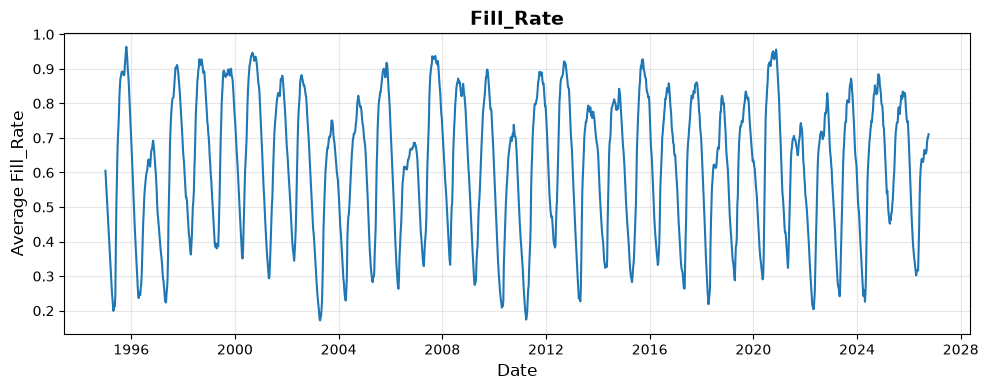

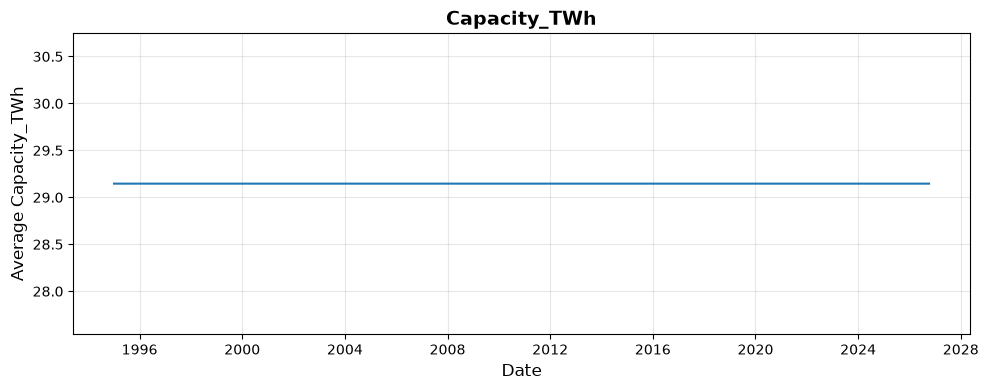

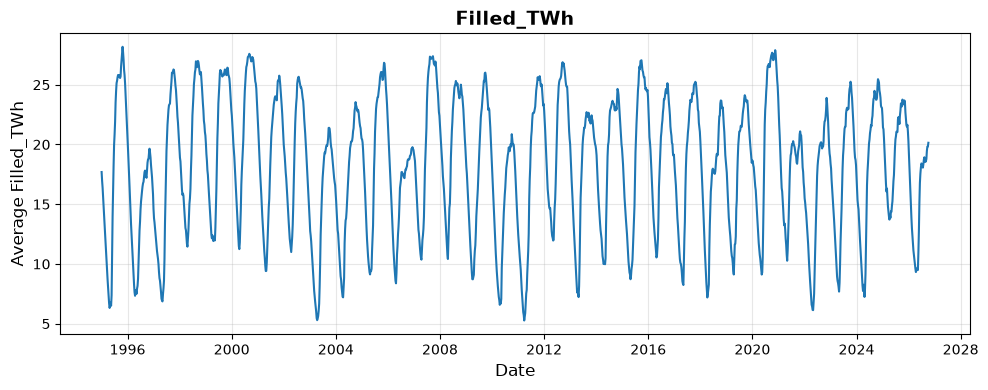

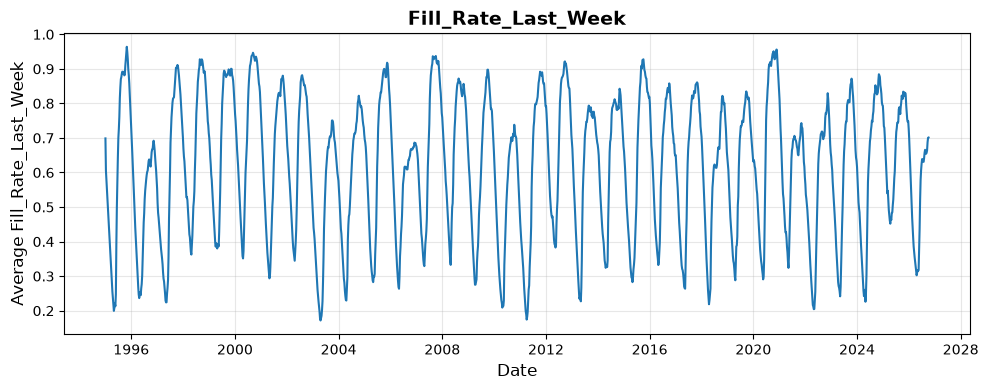

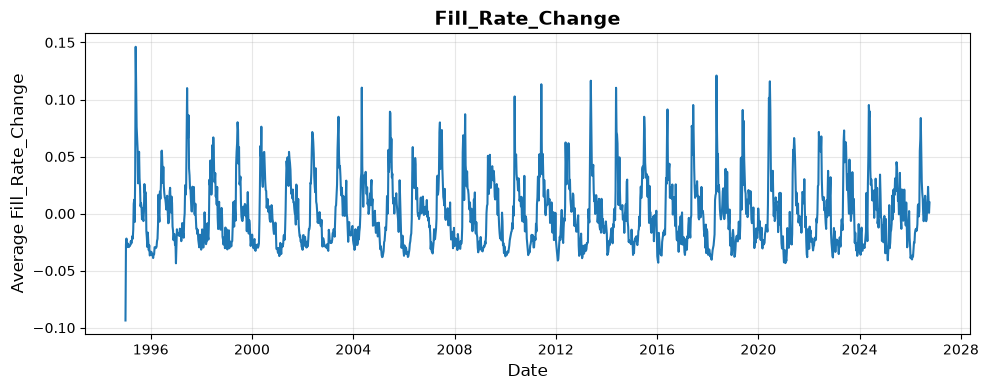

In [17]:
# Aggregate data: Group by Date and calculate the mean for all numeric metrics.
numeric_columns = ['Fill_Rate', 'Capacity_TWh', 'Filled_TWh', 'Fill_Rate_Last_Week', 'Fill_Rate_Change']
# This approach includes ALL areas without filtering, displaying a clean national average.
df_national = df_res.groupby('Date')[numeric_columns].mean().reset_index()

# Graph each column separately representing the national trend
for col in numeric_columns:
    plt.figure(figsize=(10, 4))
    plt.plot(df_national['Date'], df_national[col], color='#1f77b4', linewidth=1.5)
    plt.title(f'{col}', fontsize=14, fontweight='bold')
    plt.xlabel('Date', fontsize=12)
    plt.ylabel(f'Average {col}', fontsize=12)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

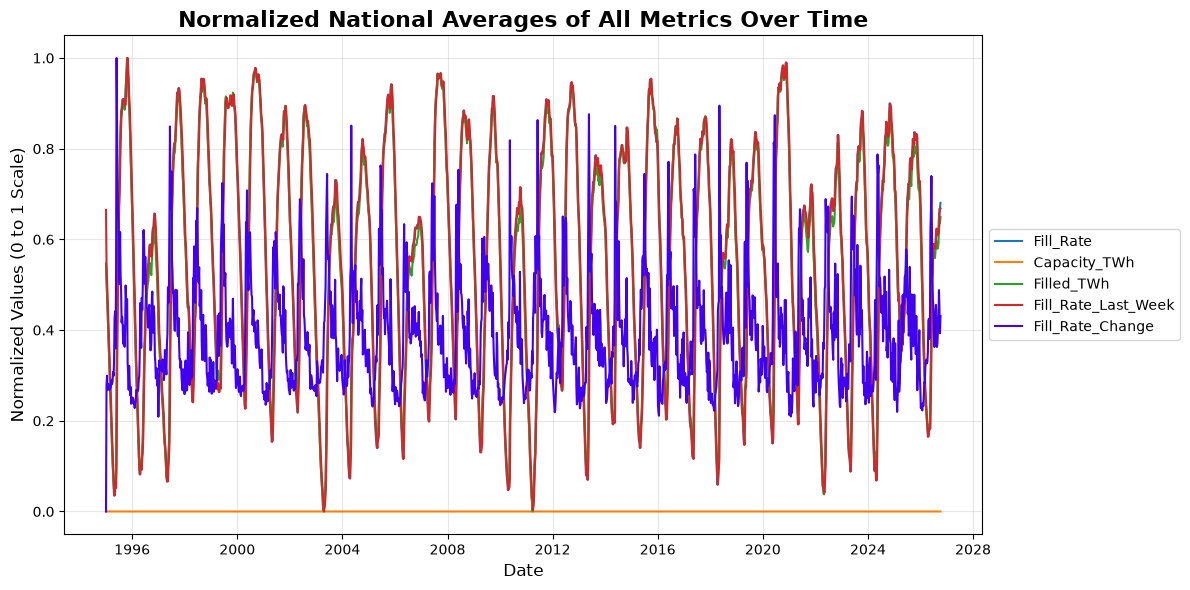

In [18]:
# Aggregate data to get the national average for all areas
df_national = df_res.groupby('Date')[numeric_columns].mean().reset_index()

# Normalize the data (Min-Max scaling) to plot everything on a single axis naturally
# This scales all metrics between 0 and 1, preserving their trends without scale distortion
df_normalized = df_national.copy()
for col in numeric_columns:
    min_val = df_national[col].min()
    max_val = df_national[col].max()
    # Avoid division by zero in case a column has a constant value
    if max_val != min_val:
        df_normalized[col] = (df_national[col] - min_val) / (max_val - min_val)
    else:
        df_normalized[col] = 0

# Plot all normalized columns together in a single graph
plt.figure(figsize=(12, 6))
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', "#4101f0"]

for i, col in enumerate(numeric_columns):
    plt.plot(df_normalized['Date'], df_normalized[col], label=col, color=colors[i], linewidth=1.5)
    
plt.title('Normalized National Averages of All Metrics Over Time', fontsize=16, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Normalized Values (0 to 1 Scale)', fontsize=12)

# Place the legend outside the plot so it doesn't cover the data lines
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Cross-border flows from the ENTSO-E API

We retrieve **physical cross-border flows (MW)** for the last two years
(Oct 2024 – Oct 2026) on three major Norwegian interconnections, in **both directions**:

- **NO1 ↔ SE3**: Oslo – Stockholm
- **NO2 ↔ DK1**: Southern Norway – Denmark (Skagerrak)
- **NO2 ↔ DE_LU**: Southern Norway – Germany (NordLink)

All six series are stored in one long-format DataFrame with the columns
`from_area`, `to_area`, `timestamp`, `flow_mw`.
Note that ENTSO-E publishes some series at **15-minute** and others at **hourly** resolution,
which is why the number of rows differs between connections.

To make the download robust, each series is requested **month by month** with a timeout and
automatic retries. The result is cached locally (`data/entsoe_crossborder_flows.parquet`,
excluded from Git), so re-running the notebook does not query the API again.
Set `FORCE_REFRESH = True` to download fresh data. 

In [6]:
import os
from pathlib import Path
import pandas as pd
from dotenv import load_dotenv
from entsoe import EntsoePandasClient

# Local cache: the API is only queried if the file does not exist yet
CACHE_FILE = Path("../data/entsoe_crossborder_flows.pkl")
FORCE_REFRESH = False   # set to True to download fresh data from the API

# Three major Norwegian interconnections (both directions are fetched)
connections = [
    ("NO_1", "SE_3"),   # Oslo - Stockholm
    ("NO_2", "DK_1"),   # Southern Norway - Denmark 
    ("NO_2", "DE_LU"),  # Southern Norway - Germany 
]

# Time window: last two years
start_date = pd.Timestamp("2024-10-01", tz="Europe/Oslo")
end_date = pd.Timestamp("2026-10-01", tz="Europe/Oslo")

if CACHE_FILE.exists() and not FORCE_REFRESH:
    flows_df = pd.read_pickle(CACHE_FILE)
    print(f"✅ Loaded cached ENTSO-E data from {CACHE_FILE}")
else:
    load_dotenv()
    entsoe_token = os.getenv("ENTSOE_TOKEN")
    if not entsoe_token:
        raise ValueError("ENTSOE_TOKEN is missing. Please check your .env file.")

    client = EntsoePandasClient(api_key=entsoe_token, timeout=60, retry_count=3, retry_delay=10)
    months = pd.date_range(start_date, end_date, freq="MS")

    frames = []
    for area_a, area_b in connections:
        for from_area, to_area in [(area_a, area_b), (area_b, area_a)]:
            print(f"Fetching {from_area} -> {to_area} ...")
            parts = []
            for m_start, m_end in zip(months[:-1], months[1:]):
                try:
                    parts.append(client.query_crossborder_flows(from_area, to_area, start=m_start, end=m_end))
                except Exception as e:
                    print(f"   ❌ {m_start:%Y-%m}: {e}")
            if parts:
                df = pd.concat(parts).rename("flow_mw").to_frame()
                df.index.name = "timestamp"
                df = df[~df.index.duplicated()].reset_index()
                df["from_area"] = from_area
                df["to_area"] = to_area
                frames.append(df)

    flows_df = pd.concat(frames, ignore_index=True)[["from_area", "to_area", "timestamp", "flow_mw"]]
    CACHE_FILE.parent.mkdir(exist_ok=True)
    flows_df.to_pickle(CACHE_FILE)
    print(f"✅ Downloaded from ENTSO-E and cached to {CACHE_FILE}")

print(flows_df.groupby(["from_area", "to_area"]).size().to_string())

✅ Loaded cached ENTSO-E data from ../data/entsoe_crossborder_flows.pkl
from_area  to_area
DE_LU      NO_2       70080
DK_1       NO_2       56466
NO_1       SE_3       43938
NO_2       DE_LU      70080
           DK_1       56466
SE_3       NO_1       43938


### Phase 3: Loading Data into Apache Cassandra via Spark

Following the assignment directives, this phase utilizes Apache Spark to handle the ingestion of the ENTSO-E cross-border flow data into a Cassandra database. Spark is ideal for distributed data processing and provides robust connectors for NoSQL databases like Cassandra.

**Key Operations:**
*   **Spark Session Initialization:** Configures the local Spark environment and dynamically downloads the DataStax Spark-Cassandra connector.
*   **Data Preparation:** Resets the Pandas DataFrame index to expose the temporal data as a standard column and converts it into a Spark DataFrame.

### Spark environment setup

The Spark Cassandra Connector (latest release 3.5.1) is built for **Spark 3.5 / Scala 2.12**.
Spark 4.x runs on Scala 2.13 only, so combining it with the connector caused a
`java.lang.NoSuchMethodError` (Scala binary incompatibility).

To fix this, the notebook runs in a dedicated environment with matching versions:

| Component | Version |
|---|---|
| Python | 3.12 |
| PySpark | 3.5.9 (Scala 2.12) |
| Java | 17 (set explicitly via `JAVA_HOME`) |
| Spark Cassandra Connector | `spark-cassandra-connector_2.12:3.5.1` |

In [7]:
import os

# Spark 3.5 requires Java 8, 11 or 17. The Mac's default Java is version 20, so Java 17
# is set explicitly before Spark starts.
# NOTE: this path is specific to this computer; on another machine, replace it with
# the local Java 17 installation (on macOS: /usr/libexec/java_home -v 17).
os.environ["JAVA_HOME"] = "/Library/Java/JavaVirtualMachines/microsoft-17.jdk/Contents/Home"

from pyspark.sql import SparkSession

# Create (or reuse) the Spark session used by all following cells.
# - connection.host / port: address of the local Cassandra database
# - jars.packages: the Spark Cassandra Connector, downloaded automatically on first run.
#   The "_2.12" suffix is the Scala version and must match Spark's Scala version
#   (PySpark 3.5 uses Scala 2.12; Spark 4 with Scala 2.13 caused a NoSuchMethodError).
spark = SparkSession.builder \
    .appName("IND320_Spark_Cassandra") \
    .config("spark.cassandra.connection.host", "127.0.0.1") \
    .config("spark.cassandra.connection.port", "9042") \
    .config("spark.jars.packages", "com.datastax.spark:spark-cassandra-connector_2.12:3.5.1") \
    .getOrCreate()

# Verify that the running versions are compatible with the connector
print("Spark:", spark.version)
print("Scala:", spark.sparkContext._jvm.scala.util.Properties.versionString())
print("Java: ", spark.sparkContext._jvm.java.lang.System.getProperty("java.version"))

26/10/19 16:48:51 WARN Utils: Your hostname, MacBook-Pro-di-Giorgio.local resolves to a loopback address: 127.0.0.1; using 192.168.11.28 instead (on interface en0)
26/10/19 16:48:51 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


:: loading settings :: url = jar:file:/Users/giorgiocrupi/miniconda3/envs/ind320/lib/python3.12/site-packages/pyspark/jars/ivy-2.5.3.jar!/org/apache/ivy/core/settings/ivysettings.xml


Ivy Default Cache set to: /Users/giorgiocrupi/.ivy2/cache
The jars for the packages stored in: /Users/giorgiocrupi/.ivy2/jars
com.datastax.spark#spark-cassandra-connector_2.12 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-f79f8a6e-9445-4142-ba39-80890a6a18f2;1.0
	confs: [default]
	found com.datastax.spark#spark-cassandra-connector_2.12;3.5.1 in central
	found com.datastax.spark#spark-cassandra-connector-driver_2.12;3.5.1 in central
	found org.scala-lang.modules#scala-collection-compat_2.12;2.11.0 in central
	found org.apache.cassandra#java-driver-core-shaded;4.18.1 in central
	found com.datastax.oss#native-protocol;1.5.1 in central
	found com.datastax.oss#java-driver-shaded-guava;25.1-jre-graal-sub-1 in central
	found com.typesafe#config;1.4.1 in central
	found org.slf4j#slf4j-api;1.7.26 in central
	found io.dropwizard.metrics#metrics-core;4.1.18 in central
	found org.hdrhistogram#HdrHistogram;2.1.12 in central
	found org.reactivestreams#reacti

Spark: 3.5.9
Scala: version 2.12.18
Java:  17.0.20.1


### Cassandra table design

All connections and directions are stored in a single table:

`PRIMARY KEY ((from_area, to_area), timestamp)`

- **Partition key** `(from_area, to_area)`: each connection/direction is stored together,
  which matches how the data is queried for the plots.
- **Clustering key** `timestamp`: rows are sorted by time within each partition.

Because the primary key is unique, writing the same data again overwrites existing rows
instead of creating duplicates.

In [8]:
from cassandra.cluster import Cluster

# Quick check: we should have 6 connection/direction pairs
print(flows_df.groupby(["from_area", "to_area"]).size().to_string(), "\n")

# 1. Connect to the local Cassandra cluster
cluster = Cluster(["127.0.0.1"], port=9042)
session = cluster.connect()

# 2. Keyspace
keyspace_name = "ind320_energy_data"
session.execute(f"""
    CREATE KEYSPACE IF NOT EXISTS {keyspace_name}
    WITH replication = {{'class': 'SimpleStrategy', 'replication_factor': 1}};
""")
session.set_keyspace(keyspace_name)

# 3. One table for all connections and directions.
#    Partition key (from_area, to_area): each direction is stored together.
#    Clustering key timestamp: rows are sorted by time inside each partition.
session.execute("""
    CREATE TABLE IF NOT EXISTS crossborder_flows (
        from_area text,
        to_area   text,
        timestamp timestamp,
        flow_mw   double,
        PRIMARY KEY ((from_area, to_area), timestamp)
    ) WITH CLUSTERING ORDER BY (timestamp ASC);
""")
print("✅ Table 'crossborder_flows' ready.")

cluster.shutdown()

from_area  to_area
DE_LU      NO_2       70080
DK_1       NO_2       56466
NO_1       SE_3       43938
NO_2       DE_LU      70080
           DK_1       56466
SE_3       NO_1       43938 

✅ Table 'crossborder_flows' ready.


### From pandas to Spark

The pandas DataFrame is converted to a Spark DataFrame with an **explicit schema**
identical to the Cassandra table. Values are converted to plain Python types
(`datetime`, `float`), as required by Spark 3.5, and timestamps keep their time zone
so that Cassandra stores the correct instant.

In [9]:
from pyspark.sql.types import StructType, StructField, StringType, TimestampType, DoubleType

# Same schema as the Cassandra table 'crossborder_flows'
schema = StructType([
    StructField("from_area", StringType(), False),
    StructField("to_area", StringType(), False),
    StructField("timestamp", TimestampType(), False),
    StructField("flow_mw", DoubleType(), True),
])

# Build rows from the pandas DataFrame (timezone-aware timestamps are preserved)
# Convert pandas/numpy values to plain Python types (required by Spark 3.5)
rows = [
    (from_area, to_area, ts.to_pydatetime(), float(flow))
    for from_area, to_area, ts, flow in flows_df[["from_area", "to_area", "timestamp", "flow_mw"]]
        .itertuples(index=False, name=None)
]

spark_df = spark.createDataFrame(rows, schema=schema)

spark_df.printSchema()
spark_df.show(3, truncate=False)
print("Rows:", spark_df.count())

root
 |-- from_area: string (nullable = false)
 |-- to_area: string (nullable = false)
 |-- timestamp: timestamp (nullable = false)
 |-- flow_mw: double (nullable = true)



26/10/19 16:49:46 WARN TaskSetManager: Stage 0 contains a task of very large size (2090 KiB). The maximum recommended task size is 1000 KiB.
26/10/19 16:49:55 WARN PythonRunner: Detected deadlock while completing task 0.0 in stage 0 (TID 0): Attempting to kill Python Worker


+---------+-------+-------------------+-------+
|from_area|to_area|timestamp          |flow_mw|
+---------+-------+-------------------+-------+
|NO_1     |SE_3   |2024-10-01 00:00:00|0.0    |
|NO_1     |SE_3   |2024-10-01 01:00:00|0.0    |
|NO_1     |SE_3   |2024-10-01 02:00:00|0.0    |
+---------+-------+-------------------+-------+
only showing top 3 rows



26/10/19 16:50:04 WARN TaskSetManager: Stage 1 contains a task of very large size (2090 KiB). The maximum recommended task size is 1000 KiB.


Rows: 340968


### Writing to Cassandra with Spark

The data is written through the Spark Cassandra Connector (`org.apache.spark.sql.cassandra`)
in `append` mode.

In [13]:
# Load the data into Cassandra using the Spark Connector
print("Writing data to Cassandra via Spark...")

try:
    spark_df.write \
        .format("org.apache.spark.sql.cassandra") \
        .options(table="crossborder_flows", keyspace="ind320_energy_data") \
        .mode("append") \
        .save()

    print("✅ Data successfully loaded into Cassandra!")
except Exception as e:
    print(f"❌ Spark-Cassandra write error: {e}")

Writing data to Cassandra via Spark...


26/10/19 16:55:15 WARN TaskSetManager: Stage 7 contains a task of very large size (2090 KiB). The maximum recommended task size is 1000 KiB.


✅ Data successfully loaded into Cassandra!


### Verification

The table is read back from Cassandra with Spark to check that all
340,968 rows (6 connection/direction series) were stored correctly.

In [15]:
check_df = spark.read.format("org.apache.spark.sql.cassandra") \
    .options(table="crossborder_flows", keyspace="ind320_energy_data") \
    .load()

print("Rows in Cassandra:", check_df.count())
check_df.groupBy("from_area", "to_area").count().orderBy("from_area", "to_area").show()


Rows in Cassandra: 340968


+---------+-------+-----+
|from_area|to_area|count|
+---------+-------+-----+
|    DE_LU|   NO_2|70080|
|     DK_1|   NO_2|56466|
|     NO_1|   SE_3|43938|
|     NO_2|  DE_LU|70080|
|     NO_2|   DK_1|56466|
|     SE_3|   NO_1|43938|
+---------+-------+-----+



### Extraction with Spark

The relevant columns (`from_area`, `to_area`, `timestamp`, `flow_mw`) are extracted from
Cassandra with Spark. Since some series are published at 15-minute and others at hourly
resolution, all data is aggregated to **hourly values**: the mean power (MW) over one hour
equals the energy (MWh) transferred in that hour. A `direction` label (e.g. `NO_2 → DE_LU`)
is added for plotting.

In [ ]:
from pyspark.sql import functions as F

# Use Norwegian local time for all time operations
spark.conf.set("spark.sql.session.timeZone", "Europe/Oslo")

# 1. Extract the relevant columns from Cassandra
raw_df = spark.read.format("org.apache.spark.sql.cassandra") \
    .options(table="crossborder_flows", keyspace="ind320_energy_data") \
    .load() \
    .select("from_area", "to_area", "timestamp", "flow_mw")

# 2. Harmonise resolution: some series are 15-min, others hourly.
#    The mean MW over one hour equals the energy (MWh) for that hour.
hourly_df = (
    raw_df
    .withColumn("hour", F.date_trunc("hour", "timestamp"))
    .groupBy("from_area", "to_area", "hour")
    .agg(F.avg("flow_mw").alias("energy_mwh"))
    .withColumn("direction", F.concat_ws(" → ", "from_area", "to_area"))
    .withColumnRenamed("hour", "timestamp")
    .cache()
)

hourly_df.orderBy("direction", "timestamp").show(5, truncate=False)
hourly_df.groupBy("direction").count().orderBy("direction").show(truncate=False)

+---------+-------+-------------------+------------------+------------+
|from_area|to_area|timestamp          |energy_mwh        |direction   |
+---------+-------+-------------------+------------------+------------+
|DE_LU    |NO_2   |2024-10-01 00:00:00|1076.6475         |DE_LU → NO_2|
|DE_LU    |NO_2   |2024-10-01 01:00:00|1388.6799999999998|DE_LU → NO_2|
|DE_LU    |NO_2   |2024-10-01 02:00:00|1392.8675         |DE_LU → NO_2|
|DE_LU    |NO_2   |2024-10-01 03:00:00|1184.4925         |DE_LU → NO_2|
|DE_LU    |NO_2   |2024-10-01 04:00:00|600.7624999999999 |DE_LU → NO_2|
+---------+-------+-------------------+------------------+------------+
only showing top 5 rows



+------------+-----+
|direction   |count|
+------------+-----+
|DE_LU → NO_2|17520|
|DK_1 → NO_2 |17520|
|NO_1 → SE_3 |17520|
|NO_2 → DE_LU|17520|
|NO_2 → DK_1 |17520|
|SE_3 → NO_1 |17520|
+------------+-----+



### Pie chart: yearly energy exchange on one connection

The pie chart shows the **total energy transferred in 2025** on the selected interconnection,
split by direction:

- **Export from Norway**: energy flowing from the Norwegian price area to the foreign area
- **Import to Norway**: energy flowing from the foreign area into Norway

2025 is used because it is the only **complete calendar year** in the two-year data window
(Oct 2024 – Oct 2026). The yearly totals are computed in Spark by summing the hourly energy
values (MWh) and are shown in **TWh**.

The default connection is **NO2 ↔ DE_LU (NordLink)**, one of Norway's largest interconnectors
(1,400 MW), linking Norwegian hydropower with Germany, the largest electricity market in Europe.
Another connection can be selected by changing `CONNECTION`.

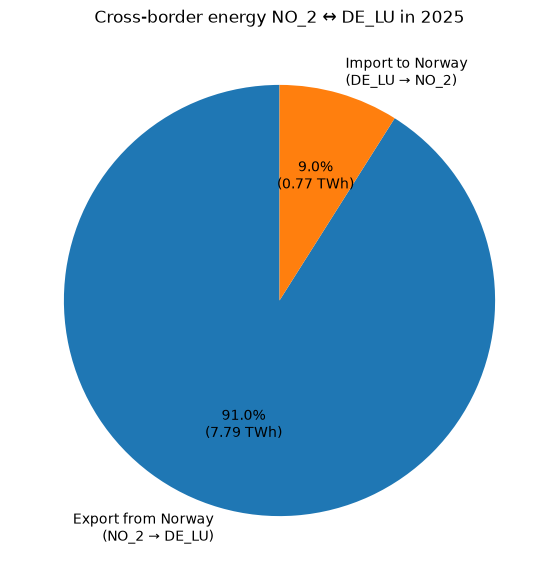

Export from Norway (NO_2 → DE_LU): 7.79 TWh
Import to Norway (DE_LU → NO_2): 0.77 TWh


In [ ]:
import matplotlib.pyplot as plt

# --- Settings: year and connection shown in the pie chart ---
# 2025 is the only complete calendar year in the data window (Oct 2024 – Sep 2026)
YEAR = 2025
CONNECTION = ("NO_2", "DE_LU")   # options: ("NO_1", "SE_3"), ("NO_2", "DK_1"), ("NO_2", "DE_LU")

# (Norwegian area, foreign area)
no_area, foreign_area = CONNECTION

# Aggregate the yearly energy per direction with Spark
pie_rows = (
    hourly_df
    # keep only the selected year
    .filter(F.year("timestamp") == YEAR)
    # keep both directions of the selected connection (export and import)
    .filter(
        ((F.col("from_area") == no_area) & (F.col("to_area") == foreign_area)) |
        ((F.col("from_area") == foreign_area) & (F.col("to_area") == no_area))
    )
    # remove missing values (NaN), which would make the sum NaN
    .filter(~F.isnan("energy_mwh"))
    # label each row: flows that start in a Norwegian area ("NO_...") are exports
    .withColumn(
        "flow_type",
        F.when(F.col("from_area").startswith("NO"), "Export from Norway").otherwise("Import to Norway"),
    )
    # each row is the energy of one hour (MWh), so the sum is the total energy of the year
    .groupBy("flow_type", "direction")
    .agg(F.sum("energy_mwh").alias("total_mwh"))
    .orderBy("flow_type")
    # bring the two aggregated rows from Spark to Python for plotting
    .collect()
)

# Prepare labels and values for the pie chart (MWh -> TWh: divide by 1,000,000)
labels = [f"{r['flow_type']}\n({r['direction']})" for r in pie_rows]
values_twh = [r["total_mwh"] / 1e6 for r in pie_rows]
total_twh = sum(values_twh)

fig, ax = plt.subplots(figsize=(7, 7))
ax.pie(
    values_twh,
    labels=labels,
    # autopct receives the percentage of each slice; the energy in TWh is shown as well
    autopct=lambda p: f"{p:.1f}%\n({p * total_twh / 100:.2f} TWh)",
    startangle=90,   # start the first slice at the top
)
ax.set_title(f"Cross-border energy {no_area} ↔ {foreign_area} in {YEAR}")
plt.show()

# Print the exact totals below the chart (chr(10) is the newline character used in the labels)
for label, value in zip(labels, values_twh):
    print(f"{label.replace(chr(10), ' ')}: {value:.2f} TWh")

#### Interpretation

In 2025, a total of about **8.6 TWh** was exchanged over NordLink:

- **Export from Norway (NO2 → DE_LU): 7.79 TWh (≈ 91 %)**
- **Import to Norway (DE_LU → NO2): 0.77 TWh (≈ 9 %)**

The connection was therefore used **mainly for export**, with a net export of about **7.0 TWh**
from Southern Norway to Germany. For comparison, running at full capacity (1,400 MW) for a
whole year would correspond to about 12.3 TWh in one direction, so the export direction used
roughly two thirds of the cable's theoretical annual capacity.

This pattern is consistent with Norway's role as a flexible hydropower exporter: power usually
flows towards Germany, where prices are generally higher, while imports occur mainly in periods
with high German wind and solar production.




### Line chart: hourly flows in January

The line chart shows the **hourly cross-border flows in January 2025** for all three
interconnections. Each panel represents one connection, with **separate lines for each direction**:

- **Export**: from the Norwegian price area to the foreign area
- **Import**: from the foreign area into Norway

The data is extracted from the hourly Spark DataFrame by filtering on the first month of the year.
Showing one panel per connection keeps the six lines readable.

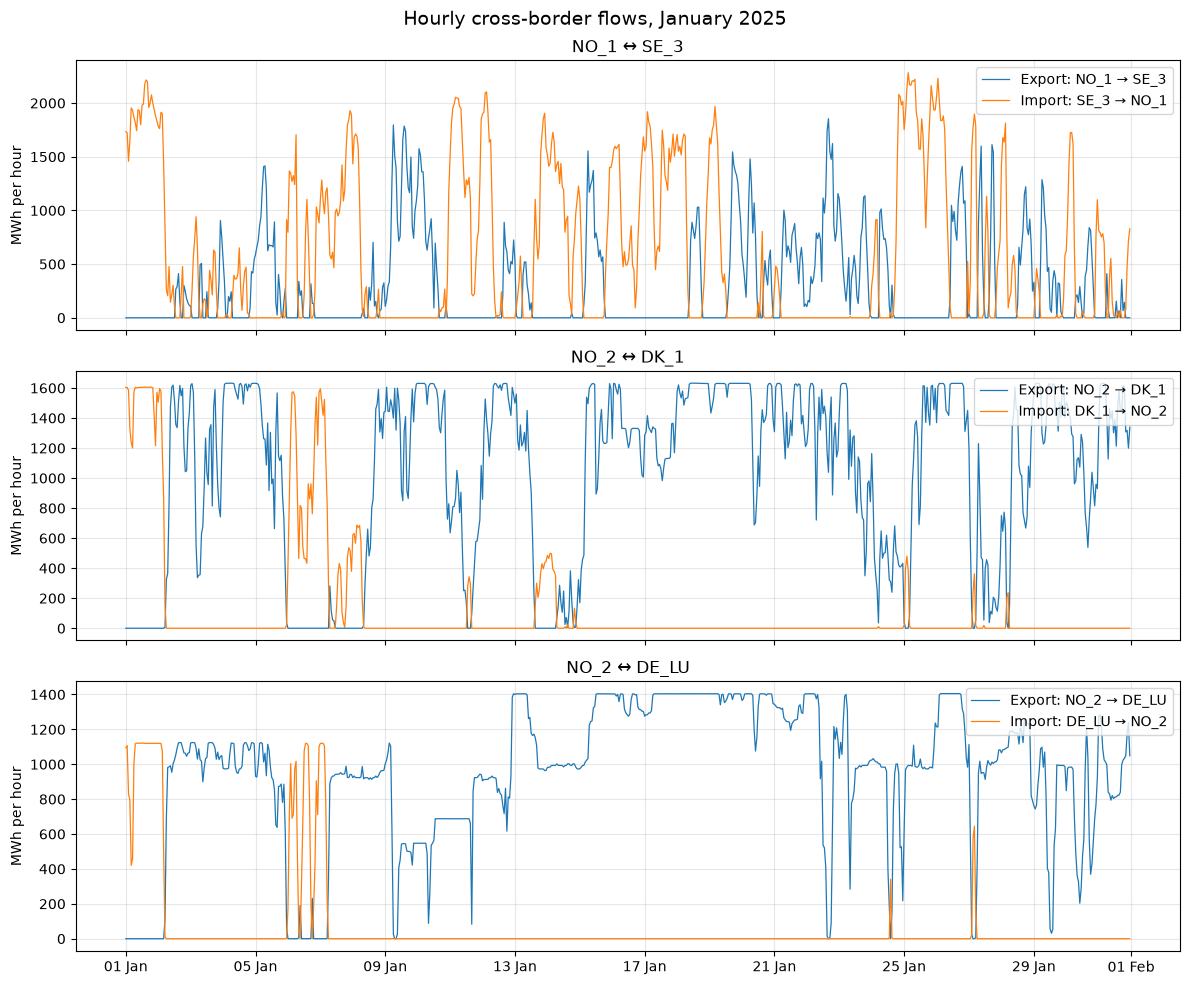

In [ ]:
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from collections import defaultdict

# --- Setting: January of this year is shown (January 2025 and January 2026 are both available) ---
JAN_YEAR = 2025

# Extract January data for all connections and directions with Spark
line_rows = (
    hourly_df
    # keep only January of the selected year
    .filter((F.year("timestamp") == JAN_YEAR) & (F.month("timestamp") == 1))
    # remove missing values (NaN), which would create gaps or errors in the plot
    .filter(~F.isnan("energy_mwh"))
    # only the columns needed for the chart
    .select("direction", "timestamp", "energy_mwh")
    .orderBy("direction", "timestamp")
    # bring the rows from Spark to Python for plotting
    .collect()
)

# Group the rows into one time series per direction:
# series["NO_2 → DE_LU"] = ([timestamps], [values])
series = defaultdict(lambda: ([], []))
for r in line_rows:
    xs, ys = series[r["direction"]]
    xs.append(r["timestamp"])
    ys.append(r["energy_mwh"])

# One panel per connection (stacked vertically, sharing the same time axis),
# with one line per direction, so the six lines stay readable
fig, axes = plt.subplots(len(connections), 1, figsize=(12, 10), sharex=True)

for ax, (no_area, foreign_area) in zip(axes, connections):
    # Export = from the Norwegian area to the foreign area; Import = the opposite
    for from_area, to_area, flow_type in [
        (no_area, foreign_area, "Export"),
        (foreign_area, no_area, "Import"),
    ]:
        direction = f"{from_area} → {to_area}"
        xs, ys = series[direction]
        ax.plot(xs, ys, linewidth=0.9, label=f"{flow_type}: {direction}")
    ax.set_title(f"{no_area} ↔ {foreign_area}")
    ax.set_ylabel("MWh per hour")   # hourly energy = average power over the hour
    ax.legend(loc="upper right")
    ax.grid(alpha=0.3)

# Show dates as "01 Jan", "08 Jan", ... on the shared x-axis
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
fig.suptitle(f"Hourly cross-border flows, January {JAN_YEAR}", fontsize=14)
fig.tight_layout()
plt.show()

### Storing the Spark data in MongoDB

The hourly data extracted and aggregated with Spark (`hourly_df`) is inserted into
**MongoDB Atlas**, in the database `ind320_energy_data` and the collection
`crossborder_flows_hourly`.

- The connection string is loaded from the `.env` file, so no credentials appear in the notebook.
- Each document contains `from_area`, `to_area`, `direction`, `timestamp` and `energy_mwh`.
- Timestamps are stored in **UTC**, MongoDB's standard, to avoid ambiguity around
  daylight saving time changes.
- The collection is replaced on each run and a **unique index** on `(direction, timestamp)`
  guarantees there are no duplicate records.
- Documents are inserted in batches of 10,000 for a reliable transfer to the cloud.

Result: **105,120 documents** (6 directions × 17,520 hours).

In [ ]:
import os
from datetime import datetime, timezone
from dotenv import load_dotenv
from pymongo import MongoClient, ASCENDING

# Load the MongoDB Atlas connection string from the hidden .env file
load_dotenv()
MONGO_URI = os.getenv("MONGO_URI")
if not MONGO_URI:
    raise ValueError("MONGO_URI is missing. Please check your .env file.")

# 1. Collect the hourly data extracted with Spark.
#    Epoch seconds are used so that the exact UTC instant is preserved.
mongo_rows = (
    hourly_df
    .filter(~F.isnan("energy_mwh"))
    .select(
        "from_area",
        "to_area",
        "direction",
        F.unix_timestamp("timestamp").alias("epoch"),
        "energy_mwh",
    )
    .collect()
)

documents = [
    {
        "from_area": r["from_area"],
        "to_area": r["to_area"],
        "direction": r["direction"],
        "timestamp": datetime.fromtimestamp(r["epoch"], tz=timezone.utc),
        "energy_mwh": float(r["energy_mwh"]),
    }
    for r in mongo_rows
]
print(f"Prepared {len(documents):,} documents from Spark")

# 2. Write to MongoDB Atlas (the collection is replaced on each run to avoid duplicates)
client = MongoClient(MONGO_URI)
collection = client["ind320_energy_data"]["crossborder_flows_hourly"]
collection.drop()

BATCH_SIZE = 10_000
for i in range(0, len(documents), BATCH_SIZE):
    collection.insert_many(documents[i:i + BATCH_SIZE])

collection.create_index([("direction", ASCENDING), ("timestamp", ASCENDING)], unique=True)

# 3. Verify
print(f"✅ Documents in MongoDB: {collection.count_documents({}):,}")
print("Example document:", collection.find_one({}, {"_id": 0}))

client.close()

Prepared 105,120 documents from Spark
✅ Documents in MongoDB: 105,120
Example document: {'from_area': 'NO_1', 'to_area': 'SE_3', 'direction': 'NO_1 → SE_3', 'timestamp': datetime.datetime(2024, 10, 25, 1, 0), 'energy_mwh': 0.0}




<!-- ===== CELL 1 (Markdown) ===== -->
## Streamlit app: source code

The code below is shown for documentation only (Markdown, not executed in this notebook). The app runs in its own uv environment and is deployed on Streamlit Community Cloud; the files are also available in the GitHub repository.


<!-- ===== CELL 2 (Markdown) ===== -->
### Entry point and navigation menu (`app.py`)

Defines the sidebar menu with `st.navigation`. The app is started with `uv run streamlit run app.py`.

```python
"""
IND320 - Norwegian Energy Dashboard (Streamlit entry point)

Run locally (from the project folder) with:
    uv run streamlit run app.py

This file only defines the navigation menu. Every page lives in its own .py file
and is executed by Streamlit when the user selects it in the sidebar.
"""
import streamlit as st

# set_page_config must be the first Streamlit command that is executed.
# It sets the title shown in the browser tab and uses the full browser width ("wide").
st.set_page_config(page_title="IND320 Energy Dashboard", layout="wide")

# st.navigation builds the sidebar menu from a dictionary:
#   - key   = section header shown in the sidebar ("" means no header)
#   - value = list of st.Page objects (file path, title shown in the menu, icon)
# When st.navigation is used, Streamlit no longer adds the files in the pages/ folder
# automatically: only the pages listed here appear in the menu.
# The icons are Streamlit's built-in Material Symbols (":material/<name>:"),
# so no extra library is required.
pg = st.navigation(
    {
        "": [
            # default=True makes this the page shown when the app is opened
            st.Page("home.py", title="Home", icon=":material/home:", default=True),
        ],
        "Reservoirs (NVE)": [
            st.Page("pages/2_Table.py", title="Overview table", icon=":material/table_chart:"),
            st.Page("pages/3_Plot.py", title="Trends", icon=":material/show_chart:"),
        ],
        "Cross-border flows (ENTSO-E)": [
            st.Page("pages/4_Cross_Border_Flows.py", title="Cross-border flows", icon=":material/swap_horiz:"),
        ],
    }
)

# Run the page currently selected by the user
pg.run()
```

<!-- ===== CELL 3 (Markdown) ===== -->
### Page 1 – Home (`home.py`)

Landing page with a short description of the two data sources and links to the other pages.

```python
"""
Page: Home

Landing page of the dashboard. It briefly explains the two data sources and offers
direct links to the other pages (in addition to the sidebar menu defined in app.py).
"""
import streamlit as st

st.title("Norwegian Energy Dashboard")

# st.write renders Markdown, so **text** is shown in bold
st.write(
    "An interactive dashboard for **IND320**, combining Norwegian hydropower reservoir statistics "
    "with cross-border electricity flows between Norway and its neighbours."
)

st.write("---")   # horizontal separator line

# st.columns splits the page into side-by-side columns;
# everything written inside a "with colX:" block is placed in that column.
col1, col2 = st.columns(2)

with col1:
    # Material icons can also be used inside text and headers
    st.subheader(":material/water_drop: Reservoirs")
    st.write(
        "Weekly reservoir statistics from **NVE (Magasinstatistikk API)**, available for "
        "electricity price areas, Norway as a whole and watercourse areas."
    )
    # st.page_link creates a clickable link to another page of the app.
    # The path must match the one used in st.Page (app.py).
    st.page_link("pages/2_Table.py", label="Overview table", icon=":material/table_chart:")
    st.page_link("pages/3_Plot.py", label="Trends", icon=":material/show_chart:")

with col2:
    st.subheader(":material/electric_bolt: Cross-border flows")
    st.write(
        "Hourly physical electricity flows on three major Norwegian interconnections, from "
        "**ENTSO-E**, processed with Spark and Cassandra and stored in MongoDB."
    )
    st.page_link("pages/4_Cross_Border_Flows.py", label="Cross-border flows", icon=":material/swap_horiz:")

st.write("---")

# st.caption shows small, grey helper text
st.caption("Use the sidebar menu or the links above to navigate between pages.")
```

<!-- ===== CELL 4 (Markdown) ===== -->
### Page 2 – Reservoirs: Overview table (`pages/2_Table.py`)

Reads the NVE Magasinstatistikk API and shows a table with `LineChartColumn` trend lines, one per area of the type selected with `st.radio`.

```python
"""
Page: Reservoirs - Overview Table

Shows one row per variable of the NVE reservoir data. For the selected area type,
the table contains one small trend line (LineChartColumn) per area number, showing
the weekly values of the first available month.
Data source: NVE Magasinstatistikk public API (replaces the former reservoirs.csv file).
"""
import streamlit as st
import pandas as pd
import requests

# Browser-tab title and full-width layout for this page
st.set_page_config(page_title="Data Table", layout="wide")
st.title("Reservoirs: Overview Table")

# Public NVE endpoint that returns the full weekly reservoir history as JSON (no API key needed)
NVE_URL = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData"


# st.cache_data stores the return value of the function. Streamlit re-runs the whole script
# every time the user interacts with a widget, so without caching the API would be called on
# every click. With ttl=24h the API is called at most once a day; later runs reuse the result.
@st.cache_data(ttl=24 * 3600)
def load_data():
    # 1. Retrieve the reservoir statistics directly from the NVE Magasinstatistikk API
    response = requests.get(NVE_URL, timeout=60)
    response.raise_for_status()   # stop with a clear error if the API does not answer correctly
    df = pd.DataFrame(response.json())   # list of JSON records -> DataFrame

    # 2. Translate the Norwegian column names to English
    column_translation = {
        'dato_Id': 'Date_Id', 'omrType': 'Area_Type', 'omrnr': 'Area_Number',
        'iso_aar': 'Year', 'iso_uke': 'Week', 'fyllingsgrad': 'Fill_Rate',
        'kapasitet_TWh': 'Capacity_TWh', 'fylling_TWh': 'Filled_TWh',
        'neste_Publiseringsdato': 'Next_Publishing_Date',
        'fyllingsgrad_forrige_uke': 'Fill_Rate_Last_Week',
        'endring_fyllingsgrad': 'Fill_Rate_Change'
    }
    df.rename(columns=column_translation, inplace=True)

    # 3. Convert ISO year + ISO week to a real date (the Monday of that week, '%G-%V-%u'),
    #    and add a "YYYY-MM" string used to select months
    df['Date'] = pd.to_datetime(df['Year'].astype(str) + '-' + df['Week'].astype(str) + '-1', format='%G-%V-%u')
    df['Month_Str'] = df['Date'].dt.strftime('%Y-%m')

    # 4. The API returns the records unsorted, so sort them chronologically
    #    (otherwise the trend lines would zig-zag)
    return df.sort_values(['Date', 'Area_Number']).reset_index(drop=True)


df = load_data()

# Numeric variables shown as rows of the table
numeric_columns = ['Fill_Rate', 'Capacity_TWh', 'Filled_TWh', 'Fill_Rate_Last_Week', 'Fill_Rate_Change']

# Human-readable descriptions of the NVE area types, shown next to the radio buttons
AREA_TYPE_DESCRIPTIONS = {
    "EL": "Electricity price areas",
    "NO": "Norway as a whole",
    "VASS": "Watercourse areas",
}

# --- WIDGET: radio buttons for the area type ---
# st.radio returns the selected value. format_func only changes the label that is displayed
# (e.g. "EL - Electricity price areas"); the returned value is still "EL".
area_types = sorted(df['Area_Type'].unique())
area_type = st.radio(
    "Select area type:",
    area_types,
    horizontal=True,
    format_func=lambda t: f"{t} – {AREA_TYPE_DESCRIPTIONS.get(t, '')}",
)

df_type = df[df['Area_Type'] == area_type]

# Isolate the first available month for the selected area type
first_month = df_type['Month_Str'].min()
df_first_month = df_type[df_type['Month_Str'] == first_month]
area_numbers = sorted(df_first_month['Area_Number'].unique())

st.write(f"### Trend Analysis for the First Month: {first_month} ({area_type}, {len(area_numbers)} areas)")

# Build the table: one row per variable, one column per area number.
# Each cell contains a list of weekly values, which LineChartColumn draws as a small line.
summary_data = []
for col in numeric_columns:
    row = {"Variable Name": col}
    for area in area_numbers:
        values = (
            df_first_month[df_first_month['Area_Number'] == area]
            .sort_values('Date')[col]
            .dropna()          # missing values would break the small chart
            .astype(float)     # plain floats are required by LineChartColumn
            .tolist()
        )
        row[f"Area {area}"] = values
    summary_data.append(row)

summary_df = pd.DataFrame(summary_data)

# column_config tells st.dataframe how to display each column:
# TextColumn for the variable name, LineChartColumn (a small line chart) for each area.
column_config = {"Variable Name": st.column_config.TextColumn("Column Name", width="medium")}
for area in area_numbers:
    column_config[f"Area {area}"] = st.column_config.LineChartColumn(
        f"{area_type} {area}",   # column header shown in the table
        help=f"Weekly values in {first_month} for {area_type} area {area}",   # tooltip
    )

st.dataframe(summary_df, column_config=column_config, hide_index=True, use_container_width=True)

# st.expander creates a collapsible box, used here to document the data source
with st.expander("About the data"):
    st.markdown(
        """
- **Source:** NVE (Norwegian Water Resources and Energy Directorate), *Magasinstatistikk* public API.
- **Content:** weekly reservoir statistics (filling rate, capacity, stored energy) for each area.
- **Area types:** **EL** = electricity price areas (NO1–NO5), **NO** = Norway as a whole,
  **VASS** = watercourse areas.
- **Table:** one row per variable; each trend line shows the weekly values of the first
  available month for one area.
- The API response is cached for 24 hours to keep the app fast.
"""
    )
```

<!-- ===== CELL 5 (Markdown) ===== -->
### Page 3 – Reservoirs: Trends (`pages/3_Plot.py`)

Interactive chart with `st.radio` (area type), `st.select_slider` (range of months to load) and `st.selectbox` (variable).

```python
"""
Page: Reservoirs - Trends

Interactive chart of the NVE reservoir data:
  - st.radio        -> area type (EL, NO, VASS); one line per area number of that type
  - st.select_slider -> range of months to load (default: the first month)
  - st.selectbox    -> one variable, or all variables in separate panels
Data source: NVE Magasinstatistikk public API (replaces the former reservoirs.csv file).
"""
import streamlit as st
import pandas as pd
import matplotlib.pyplot as plt
import requests

# Browser-tab title and full-width layout for this page
st.set_page_config(page_title="Interactive Plot", layout="wide")
st.title("Reservoirs: Trends")

# Public NVE endpoint that returns the full weekly reservoir history as JSON (no API key needed)
NVE_URL = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData"

# Human-readable descriptions of the NVE area types, shown next to the radio buttons
AREA_TYPE_DESCRIPTIONS = {
    "EL": "Electricity price areas",
    "NO": "Norway as a whole",
    "VASS": "Watercourse areas",
}
numeric_columns = ['Fill_Rate', 'Capacity_TWh', 'Filled_TWh', 'Fill_Rate_Last_Week', 'Fill_Rate_Change']


# The NVE API has no date filter (its endpoints take no parameters), so the full series
# is downloaded once. st.cache_data with ttl=24h means the API is called at most once a day:
# Streamlit re-runs the script on every widget interaction, and later runs reuse the result.
@st.cache_data(ttl=24 * 3600)
def fetch_all_data():
    # 1. Retrieve the reservoir statistics from the API
    response = requests.get(NVE_URL, timeout=60)
    response.raise_for_status()   # stop with a clear error if the API does not answer correctly
    df = pd.DataFrame(response.json())   # list of JSON records -> DataFrame

    # 2. Translate the Norwegian column names to English
    column_translation = {
        'dato_Id': 'Date_Id', 'omrType': 'Area_Type', 'omrnr': 'Area_Number',
        'iso_aar': 'Year', 'iso_uke': 'Week', 'fyllingsgrad': 'Fill_Rate',
        'kapasitet_TWh': 'Capacity_TWh', 'fylling_TWh': 'Filled_TWh',
        'neste_Publiseringsdato': 'Next_Publishing_Date',
        'fyllingsgrad_forrige_uke': 'Fill_Rate_Last_Week',
        'endring_fyllingsgrad': 'Fill_Rate_Change'
    }
    df.rename(columns=column_translation, inplace=True)

    # 3. ISO year + ISO week -> real date (Monday of the week, '%G-%V-%u'),
    #    plus a "YYYY-MM" string used by the month slider
    df['Date'] = pd.to_datetime(df['Year'].astype(str) + '-' + df['Week'].astype(str) + '-1', format='%G-%V-%u')
    df['Month_Str'] = df['Date'].dt.strftime('%Y-%m')

    # 4. The API returns the records unsorted, so sort them chronologically
    return df.sort_values(['Date', 'Area_Number']).reset_index(drop=True)


# Second cache level: the data for each (month range, area type) chosen by the user is
# loaded once and stored separately, so moving the slider back to a range already viewed
# is instant. This is how the slider "controls the download range" of the page.
@st.cache_data
def load_range(start_month, end_month, area_type):
    df = fetch_all_data()
    mask = (
        (df['Month_Str'] >= start_month)
        & (df['Month_Str'] <= end_month)
        & (df['Area_Type'] == area_type)
    )
    return df[mask]


all_df = fetch_all_data()

# --- WIDGET 1: radio buttons for the area type ---
# format_func only changes the displayed label; the returned value is still "EL", "NO" or "VASS"
area_type = st.radio(
    "Select area type:",
    sorted(all_df['Area_Type'].unique()),
    horizontal=True,
    format_func=lambda t: f"{t} – {AREA_TYPE_DESCRIPTIONS.get(t, '')}",
)

# --- WIDGET 2: select slider controlling which months are loaded ---
# Passing a tuple as value turns the slider into a range slider with two handles.
# (first, first) makes the first available month the default selection.
unique_months = sorted(all_df.loc[all_df['Area_Type'] == area_type, 'Month_Str'].unique())
selected_months = st.select_slider(
    "Select the range of months to load:",
    options=unique_months,
    value=(unique_months[0], unique_months[0]),
)

# Load only the selected range for the selected area type
df_filtered = load_range(selected_months[0], selected_months[1], area_type)
area_numbers = sorted(df_filtered['Area_Number'].unique())
st.caption(f"Loaded {len(df_filtered):,} weekly records for {len(area_numbers)} {area_type} areas.")

# --- WIDGET 3: selectbox for the column (one variable or all of them) ---
selected_col = st.selectbox("Choose a column to plot:", ['All Columns'] + numeric_columns)

st.write("---")   # horizontal separator line

period = f"{selected_months[0]} to {selected_months[1]}"
# With only a few weeks selected, show the individual points so it is clear the data is weekly
show_markers = df_filtered['Date'].nunique() <= 60


def plot_column(ax, col):
    """Draw one line per area number for the variable `col` on the Matplotlib axis `ax`."""
    for area in area_numbers:
        d = df_filtered[df_filtered['Area_Number'] == area].sort_values('Date')
        ax.plot(d['Date'], d[col], linewidth=1.5,
                marker='o' if show_markers else None, markersize=3,
                label=f"{area_type} {area}")
    ax.grid(True, alpha=0.3)


if selected_col == 'All Columns':
    # The variables have different units (rates vs. TWh), so instead of one crowded chart
    # each variable gets its own panel (3 x 2 grid), keeping its real scale.
    fig, axes = plt.subplots(3, 2, figsize=(14, 11), sharex=True)
    axes = axes.flatten()   # 2-D grid of axes -> simple list
    for ax, col in zip(axes, numeric_columns):
        plot_column(ax, col)
        ax.set_title(col, fontsize=12, fontweight='bold')
        ax.set_ylabel(col)
    axes[-1].axis('off')   # 5 variables in a 3x2 grid: hide the empty sixth panel
    # One shared legend for the whole figure, taken from the first panel
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='lower right', ncol=2, title="Area")
    fig.suptitle(f"All Columns by {area_type} area ({period})", fontsize=16, fontweight='bold')
    for ax in axes[3:5]:   # bottom panels carry the date labels
        ax.tick_params(axis='x', rotation=45)
else:
    # Single variable: one chart, one line per area
    fig, ax = plt.subplots(figsize=(12, 6))
    plot_column(ax, selected_col)
    ax.set_title(f"{selected_col} by {area_type} area ({period})", fontsize=16, fontweight='bold')
    ax.set_xlabel("Date", fontsize=12)
    ax.set_ylabel(selected_col, fontsize=12)
    ax.legend(loc='best', title="Area")
    plt.xticks(rotation=45)

plt.tight_layout()
st.pyplot(fig)   # render the Matplotlib figure in the Streamlit page

# Collapsible box documenting the data source and the loading strategy
with st.expander("About the data"):
    st.markdown(
        """
- **Source:** NVE (Norwegian Water Resources and Energy Directorate), *Magasinstatistikk* public API.
- **Area types:** **EL** = electricity price areas, **NO** = Norway as a whole, **VASS** = watercourse areas.
- **Loading:** the NVE API has no date filter, so the full weekly series is downloaded once and
  cached for 24 hours; the month slider then determines which range of data is loaded into the chart.
- **Chart:** one line per area number; "All Columns" shows one panel per variable in its own unit.
"""
    )
```

<!-- ===== CELL 6 (Markdown) ===== -->
### Page 4 – Cross-border flows (`pages/4_Cross_Border_Flows.py`)

Reads the hourly flows from MongoDB; two `st.columns` with a pie chart (`st.radio` + `st.selectbox`) and a line chart (`st.pills`), plus an `st.expander` with the data source.

```python
"""
Page: Cross-border flows

Hourly physical electricity flows on three Norwegian interconnections, read from MongoDB Atlas.
The page is split into two columns (st.columns):
  - left : st.radio (connection) + st.selectbox (year) -> pie chart of yearly export vs. import
  - right: st.pills (any set of months)                 -> line chart of hourly flows
An st.expander below the columns documents the data source.

Data pipeline (see notebooks/api_extraction.ipynb):
ENTSO-E API -> Spark -> Cassandra -> Spark (hourly aggregation) -> MongoDB -> this page.
"""
import streamlit as st
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pymongo import MongoClient

# Browser-tab title and full-width layout for this page
st.set_page_config(page_title="Cross-Border Flows", layout="wide")
st.title("Cross-Border Electricity Flows")

# Interconnections stored in MongoDB.
# key   = label shown on the radio buttons
# value = (Norwegian price area, foreign price area), as used in the "from_area"/"to_area" fields
CONNECTIONS = {
    "NO1 ↔ SE3 (Oslo – Stockholm)": ("NO_1", "SE_3"),
    "NO2 ↔ DK1 (Skagerrak)": ("NO_2", "DK_1"),
    "NO2 ↔ DE_LU (NordLink)": ("NO_2", "DE_LU"),
}


# st.cache_resource keeps ONE MongoDB connection open and shares it across all reruns
# and users (cache_resource is meant for objects such as database connections).
@st.cache_resource
def get_collection():
    # The connection string (with password) is read from Streamlit secrets:
    # locally from .streamlit/secrets.toml (excluded from Git), and on streamlit.io from the
    # app's "Secrets" settings, so credentials never appear in the code or on GitHub.
    client = MongoClient(st.secrets["mongo"]["uri"])
    return client["ind320_energy_data"]["crossborder_flows_hourly"]


# st.cache_data stores the downloaded DataFrame for 24 hours, so the ~105,000 documents are
# fetched from MongoDB only once instead of on every widget interaction.
@st.cache_data(ttl=24 * 3600)
def load_flows():
    # {"_id": 0} excludes MongoDB's internal id field, which is not needed here
    docs = list(get_collection().find({}, {"_id": 0}))
    df = pd.DataFrame(docs)
    # Timestamps are stored in UTC in MongoDB; convert them to Norwegian local time for display
    # and drop the time-zone information so Matplotlib shows local clock times
    df["timestamp"] = (
        pd.to_datetime(df["timestamp"], utc=True)
        .dt.tz_convert("Europe/Oslo")
        .dt.tz_localize(None)
    )
    # Helper columns used by the year selector and the month pills
    df["year"] = df["timestamp"].dt.year
    df["month"] = df["timestamp"].dt.strftime("%Y-%m")
    return df


df = load_flows()

# Split the page into two equally wide columns
left, right = st.columns(2)

# ---------- LEFT COLUMN: pie chart ----------
with left:
    st.subheader("Yearly energy exchange")

    # --- WIDGET: radio buttons for the connection ---
    connection_label = st.radio("Select a connection:", list(CONNECTIONS))
    no_area, foreign_area = CONNECTIONS[connection_label]

    # --- WIDGET: selectbox for the year (a different control than the radio buttons) ---
    # 2025 is preselected because it is the only complete calendar year in the data
    years = sorted(df["year"].unique())
    year = st.selectbox("Select a year:", years, index=years.index(2025) if 2025 in years else 0)

    # Keep only the two directions of the selected connection
    conn_df = df[
        ((df["from_area"] == no_area) & (df["to_area"] == foreign_area)) |
        ((df["from_area"] == foreign_area) & (df["to_area"] == no_area))
    ].copy()
    # Label each direction: flows that start in a Norwegian area ("NO_...") are exports
    conn_df["flow_type"] = np.where(
        conn_df["from_area"].str.startswith("NO"), "Export from Norway", "Import to Norway"
    )

    # Total energy per direction in the selected year.
    # Each row is the energy of one hour in MWh, so the sum is the yearly energy;
    # dividing by 1,000,000 converts MWh to TWh.
    totals_twh = (
        conn_df[conn_df["year"] == year]
        .groupby(["flow_type", "direction"])["energy_mwh"].sum() / 1e6
    )
    total = totals_twh.sum()

    fig, ax = plt.subplots(figsize=(5, 5))
    ax.pie(
        totals_twh.values,
        labels=[f"{ft}\n({d})" for ft, d in totals_twh.index],
        # autopct receives the percentage of each slice; we also show the value in TWh
        autopct=lambda p: f"{p:.1f}%\n({p * total / 100:.2f} TWh)",
        startangle=90,
    )
    ax.set_title(f"{no_area} ↔ {foreign_area} in {year}")
    st.pyplot(fig)

    # The data covers Oct 2024 - Sep 2026, so 2024 and 2026 are partial years
    if year != 2025:
        st.caption("Note: only 2025 is a complete calendar year in the data (Oct 2024 – Sep 2026).")

# ---------- RIGHT COLUMN: line chart ----------
with right:
    st.subheader("Hourly flows")

    # January of the selected year is the default (as in the Jupyter Notebook);
    # if it is not available, the first month in the data is used instead
    month_options = sorted(conn_df["month"].unique())
    default_month = f"{year}-01" if f"{year}-01" in month_options else month_options[0]

    # --- WIDGET: pills with multi-selection, so any set of months can be chosen ---
    selected_months = st.pills(
        "Select months to include:",
        month_options,
        selection_mode="multi",
        default=[default_month],
    )

    if not selected_months:
        # Avoid an empty chart when every pill is deselected
        st.info("Select at least one month to display the line chart.")
    else:
        line_df = conn_df[conn_df["month"].isin(selected_months)]
        colors = {"Export": "tab:blue", "Import": "tab:orange"}

        fig, ax = plt.subplots(figsize=(7, 5))
        # One line per direction of the connection selected in the left column
        for from_area, to_area, flow_type in [
            (no_area, foreign_area, "Export"),
            (foreign_area, no_area, "Import"),
        ]:
            direction = f"{from_area} → {to_area}"
            series = line_df[line_df["direction"] == direction].sort_values("timestamp")
            # Plot each month separately so that non-consecutive months (e.g. Jan and Jun)
            # are not joined by a misleading straight line. Only the first piece gets a
            # legend label, so each direction appears once in the legend.
            for i, (_, part) in enumerate(series.groupby("month")):
                ax.plot(
                    part["timestamp"], part["energy_mwh"],
                    color=colors[flow_type], linewidth=0.8,
                    label=f"{flow_type}: {direction}" if i == 0 else None,
                )

        ax.set_title(f"Hourly flows {no_area} ↔ {foreign_area}")
        ax.set_xlabel("Date")
        ax.set_ylabel("MWh per hour")
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b %Y"))   # e.g. "05 Jan 2025"
        ax.grid(alpha=0.3)
        ax.legend(loc="upper right")
        fig.autofmt_xdate()   # rotate the date labels so they do not overlap
        st.pyplot(fig)

# ---------- DATA SOURCE (collapsible box below the columns) ----------
with st.expander("About the data"):
    st.markdown(
        """
- **Source:** ENTSO-E Transparency Platform, *physical cross-border flows*, retrieved with the `entsoe-py` client.
- **Period:** October 2024 – September 2026.
- **Processing:** the data was written to **Cassandra** with Spark, extracted again with Spark,
  aggregated to **hourly values** (MWh per hour), and stored in **MongoDB Atlas**,
  which this page reads from.
- **Export** = flow from the Norwegian area to the foreign area; **Import** = the opposite direction.
"""
    )
```